## Credit Stress Index Analysis V4

In [1]:
import os
import datetime as dt

from dotenv import load_dotenv
from pathlib import Path

import json
import time
from urllib.parse import urljoin, urlencode
import requests

import numpy as np
import pandas as pd

import plotly
import plotly.graph_objs as go
import plotly.express as px
import seaborn as sns
import matplotlib.pyplot as plt

from Modules.utility import Utility
from Modules.show_plot import ShowPlot
from Modules.reques_api import RequestApi
from Modules.get_market_data import GetMarketData
from Modules.stock_prices_and_market_data import ClassStockPricesMarketData
from Modules.financial import Financial
from Modules.pdf_url_to_markdown import PDFUrlToMarkdown
from Modules.webpage_to_markdown import WebpageToMarkdown
from Modules.compute_fibonacci_extension import ComputeFibonacciExtension

In [2]:
# FRED API key for accessing Federal Reserve Economic Data
FRED_API_KEY = os.getenv("FRED_API_KEY")
# Output directory for storing downloaded data
API_BASE_URL = os.getenv("API_BASE_URL", "http://localhost:8000")
request_api = RequestApi(API_BASE_URL)
get_market_data = GetMarketData(Path('/workspace/data'))
utility = Utility()
stock_prices_market_data = ClassStockPricesMarketData()
financial = Financial()
# URLからPDFをダウンロードしてMarkdownに変換するクラスのインスタンスを作成
pdf_to_md = PDFUrlToMarkdown()
# WEBページをMarkdownに変換する関数
webpage_to_markdown = WebpageToMarkdown()
# Fibonacciエクステンションを計算するクラスのインスタンスを作成
fibonacci_extension = ComputeFibonacciExtension()

In [3]:
# Date range for fetching API s
start = '2007-01-01'
end = dt.datetime.now().strftime('%Y-%m-%d')
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)

#### SJBの時系列データを取得

In [4]:
sjb = 'SJB'

response = request_api.update_stock_timeseries_data(
    code=sjb,
    market=None,
    start=start,
    end=end
)
response

{'result': True}

In [5]:
sjb_df = request_api.get_stock_time_series_data(
    code=sjb,
    market=None,
    start=start,
    end=end
)
sjb_df["date"] = pd.to_datetime(sjb_df["date"])
sjb_df

取得件数: 3912


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
0,1165760,SJB,None,2011-03-22,33.406315,33.531590,33.406315,33.531590,7700,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
1,1165761,SJB,None,2011-03-23,33.406315,33.539940,33.406315,33.539940,5900,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2,1165762,SJB,None,2011-03-24,33.347858,33.431373,33.347858,33.431373,1700,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3,1165763,SJB,None,2011-03-25,33.381256,33.397960,33.364553,33.397960,3600,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4,1165764,SJB,None,2011-03-28,33.347858,33.423023,33.339505,33.423023,99800,33.464777,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3907,1169667,SJB,None,2026-10-05,15.480000,15.520000,15.480000,15.510000,128500,15.470000,...,15.075001,61.081704,True,NaN,NaN,NaN,NaN,NaN,NaN,False
3908,1169668,SJB,None,2026-10-06,15.420000,15.450000,15.410000,15.430000,235700,15.470000,...,15.090617,65.837104,True,NaN,NaN,NaN,NaN,NaN,93.196581,False
3909,1169669,SJB,None,2026-10-07,15.450000,15.490000,15.430000,15.440000,85700,15.468000,...,15.105892,70.472979,True,NaN,NaN,NaN,NaN,NaN,NaN,False
3910,1169670,SJB,None,2026-10-08,15.450000,15.490000,15.450000,15.450000,358900,15.456000,...,15.120783,74.494152,True,NaN,NaN,NaN,NaN,NaN,NaN,False


#### DX-Yの時系列データを取得

In [6]:
dxy = 'DX-Y'
market = 'NYB'

response = request_api.update_stock_timeseries_data(
    code=dxy,
    market=market,
    start=start,
    end=end
)
response

{'result': True}

In [7]:
dx_df = request_api.get_stock_time_series_data(
    code=dxy,
    market=market,
    start=start,
    end=end
)
dx_df["date"] = pd.to_datetime(dx_df["date"])
dx_df

取得件数: 5185


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
0,1091754,DX-Y,NYB,2006-03-07,90.769997,90.860001,89.860001,89.910004,0,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
1,1091755,DX-Y,NYB,2006-03-08,90.620003,90.800003,90.430000,90.709999,0,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2,1091756,DX-Y,NYB,2006-03-09,90.750000,90.790001,90.379997,90.599998,0,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3,1091757,DX-Y,NYB,2006-03-10,90.849998,91.160004,90.589996,90.779999,0,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4,1091758,DX-Y,NYB,2006-03-13,90.540001,90.870003,90.519997,90.830002,0,90.566000,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5180,1187717,DX-Y,NYB,2026-10-05,102.169998,102.540001,101.860001,101.919998,0,101.602000,...,99.174593,8.025271,True,NaN,NaN,NaN,NaN,NaN,NaN,False
5181,1187718,DX-Y,NYB,2026-10-06,101.830002,102.290001,101.750000,102.139999,0,101.792000,...,99.206891,16.750619,True,NaN,NaN,NaN,NaN,NaN,NaN,False
5182,1187719,DX-Y,NYB,2026-10-07,102.239998,102.500000,101.889999,101.889999,0,101.887999,...,99.275607,26.278494,True,NaN,NaN,NaN,NaN,NaN,91.82906,False
5183,1187720,DX-Y,NYB,2026-10-08,102.139999,102.470001,102.029999,102.230003,0,102.039999,...,99.330177,35.055067,True,NaN,NaN,NaN,NaN,NaN,NaN,False


#### HYGの時系列データを取得

In [8]:
hyg = 'HYG'

response = request_api.update_stock_timeseries_data(
    code=hyg,
    market=None,
    start=start,
    end=end
)
response

{'result': True}

In [9]:
hyg_df = request_api.get_stock_time_series_data(
    code=hyg,
    market=None,
    start=start,
    end=end
)
hyg_df["date"] = pd.to_datetime(hyg_df["date"])
hyg_df

取得件数: 4907


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
0,1169672,HYG,None,2007-04-11,31.084785,31.096701,31.084785,31.084785,1900,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
1,1169673,HYG,None,2007-04-12,31.105623,31.105623,31.084771,31.105623,6100,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2,1169674,HYG,None,2007-04-13,31.049049,31.126499,31.049049,31.096711,3400,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3,1169675,HYG,None,2007-04-16,31.037115,31.060945,31.025199,31.060945,7600,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4,1169676,HYG,None,2007-04-17,31.022232,31.099684,31.022232,31.025212,28100,31.074655,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4902,1174574,HYG,None,2026-10-05,76.980003,77.019997,76.809998,76.889999,39142800,77.050616,...,77.430472,-36.032613,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4903,1174575,HYG,None,2026-10-06,77.269997,77.320000,77.139999,77.150002,47352500,77.027371,...,77.356343,-44.040809,False,NaN,NaN,NaN,NaN,NaN,NaN,True
4904,1174576,HYG,None,2026-10-07,77.180000,77.209999,76.930000,77.000000,59309100,77.002000,...,77.275755,-51.707504,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4905,1174577,HYG,None,2026-10-08,77.139999,77.180000,76.980003,77.070000,44872800,77.066000,...,77.207912,-58.375309,False,NaN,NaN,NaN,NaN,NaN,NaN,True


#### TLTの時系列データを取得

In [10]:
tlt = 'TLT'

response = request_api.update_stock_timeseries_data(
    code=tlt,
    market=None,
    start=start,
    end=end
)
response

{'result': True}

In [11]:
tlt_df = request_api.get_stock_time_series_data(
    code=tlt,
    market=None,
    start=start,
    end=end
)
tlt_df["date"] = pd.to_datetime(tlt_df["date"])
tlt_df

取得件数: 5182


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
0,1175486,TLT,None,2006-03-07,45.815853,45.888240,45.660736,45.707273,1692900,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
1,1175487,TLT,None,2006-03-08,45.800343,45.955455,45.733123,45.795171,1184700,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2,1175488,TLT,None,2006-03-09,45.815853,45.846875,45.640054,45.789999,282100,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3,1175489,TLT,None,2006-03-10,45.645233,45.743474,45.505631,45.665916,1086900,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4,1175490,TLT,None,2006-03-13,45.609039,45.640061,45.505631,45.572846,1740100,45.706241,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5177,1180663,TLT,None,2026-10-05,77.110001,77.260002,76.690002,77.160004,49106700,77.618303,...,78.701412,-72.457953,False,NaN,NaN,NaN,NaN,NaN,NaN,False
5178,1180664,TLT,None,2026-10-06,77.279999,77.580002,77.070000,77.169998,31085900,77.411296,...,78.433292,-74.293520,False,NaN,NaN,NaN,NaN,-85.0,NaN,False
5179,1180665,TLT,None,2026-10-07,77.150002,77.320000,76.430000,76.459999,40200000,77.134001,...,78.110772,-75.147272,False,NaN,NaN,NaN,NaN,NaN,NaN,False
5180,1180666,TLT,None,2026-10-08,77.870003,77.910004,77.070000,77.190002,49484200,77.184001,...,77.891491,-75.078972,False,NaN,NaN,NaN,NaN,NaN,NaN,True


#### FREDの月次データを取得

In [12]:
fred_url = "https://api.stlouisfed.org/fred/series/observations"
series_mapping = {
    "DFF": "effective_federal_funds_rate",  # 実効FF金利
    "DFII10": "real_10y",                   # 10年TIPS実質金利
    "FEDFUNDS": "ff_rate",                  # FF金利
    "DFEDTARU": "maximum_interest_rate",    # 上限金利
    "DFEDTARL": "minimum_interest_rate",    # 下限金利
    "DGS2": "us_treasury_2y",               # 2年米国債
    "DGS5": "us_treasury_5y",               # 5年米国債
    "DGS10": "us_treasury_10y",             # 10年米国債
    "DGS30": "us_treasury_30y",             # 30年米国債
    "M1SL": "m1_money_stock",               # M1マネーストック
    "M2SL": "m2_money_stock",               # M2マネーストック
}
observation_start = "2007-01-01"
observation_end = end
base_fred_params = {
    "api_key": FRED_API_KEY,
    "file_type": "json",
    "observation_start": observation_start,
    "observation_end": observation_end,
    "frequency": "m",
    "aggregation_method": "avg",
}
fred_dfs = []
for series_id, series_name in series_mapping.items():
    fred_params = base_fred_params.copy()
    fred_params["series_id"] = series_id
    fred_res = requests.get(fred_url, params=fred_params)
    fred_df = pd.DataFrame(fred_res.json()["observations"]).assign(**{
        "date": lambda df: pd.to_datetime(df["date"]),
        "value": lambda df: pd.to_numeric(df["value"], errors="coerce"),
        "interest_rate_type": series_name,
    })
    fred_dfs.append(fred_df)
    time.sleep(5)
    
us_treasury_df = pd.concat(fred_dfs)
us_treasury_df

,realtime_start,realtime_end,date,value,interest_rate_type
0,2026-10-11,2026-10-11,2007-01-01,5.25,effective_federal_funds_rate
1,2026-10-11,2026-10-11,2007-02-01,5.26,effective_federal_funds_rate
2,2026-10-11,2026-10-11,2007-03-01,5.26,effective_federal_funds_rate
3,2026-10-11,2026-10-11,2007-04-01,5.25,effective_federal_funds_rate
4,2026-10-11,2026-10-11,2007-05-01,5.25,effective_federal_funds_rate
...,...,...,...,...,...
231,2026-10-11,2026-10-11,2026-04-01,22756.60,m2_money_stock
232,2026-10-11,2026-10-11,2026-05-01,23013.70,m2_money_stock
233,2026-10-11,2026-10-11,2026-06-01,23114.90,m2_money_stock
234,2026-10-11,2026-10-11,2026-07-01,23217.90,m2_money_stock


### CSI v4 (Credit Stress Index v4)

#### 0. ETF日次データ品質確認
- HYG
- SJB
- TLT
- DXY

取得期間確認

欠損確認

異常値確認

In [13]:
etf_dict = {
    "HYG": hyg_df.copy(),
    "SJB": sjb_df.copy(),
    "TLT": tlt_df.copy(),
    "DXY": dx_df.copy()
}

for name, df in etf_dict.items():

    print("=" * 50)
    print(name)

    print("期間")
    print(df["date"].min(), "→", df["date"].max())

    print("\n件数")
    print(len(df))

    print("\n欠損")
    print(df[["date", "close"]].isna().sum())

    print()

HYG
期間
2007-04-11 00:00:00 → 2026-10-09 00:00:00

件数
4907

欠損
date     0
close    0
dtype: int64

SJB
期間
2011-03-22 00:00:00 → 2026-10-09 00:00:00

件数
3912

欠損
date     0
close    0
dtype: int64

TLT
期間
2006-03-07 00:00:00 → 2026-10-09 00:00:00

件数
5182

欠損
date     0
close    0
dtype: int64

DXY
期間
2006-03-07 00:00:00 → 2026-10-09 00:00:00

件数
5185

欠損
date     0
close    0
dtype: int64



#### 1. 月次代表値作成

##### Case A 

In [14]:
monthly_etfs_a = []

for name, df in etf_dict.items():
    monthly = (
        df
        .set_index("date")
        .resample("MS")
        .last()[["close"]]
        .rename(columns={"close": name})
    )

    monthly_etfs_a.append(monthly)

etf_monthly_a = pd.concat(
    monthly_etfs_a,
    axis=1
).reset_index()

display(etf_monthly_a.tail())

/tmp/ipykernel_911/298789596.py:14: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  etf_monthly_a = pd.concat(


,date,HYG,SJB,TLT,DXY
243,2026-06-01,78.465107,15.009434,85.805249,101.120003
244,2026-07-01,78.296741,15.108637,81.477568,100.019997
245,2026-08-01,78.924394,15.039195,81.825639,99.699997
246,2026-09-01,77.126854,15.450000,77.846475,101.410004
247,2026-10-01,77.209999,15.470000,77.709999,102.129997


##### Case B

In [15]:
monthly_etfs_b = []

for name, df in etf_dict.items():
    monthly = (
        df
        .set_index("date")["close"]
        .resample("MS")
        .apply(lambda x: x.tail(5).mean())
        .to_frame(name)
    )

    monthly_etfs_b.append(monthly)

etf_monthly_b = pd.concat(
    monthly_etfs_b,
    axis=1
).reset_index()

display(etf_monthly_b.tail())

/tmp/ipykernel_911/1907446383.py:14: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  etf_monthly_b = pd.concat(


,date,HYG,SJB,TLT,DXY
243,2026-06-01,78.392521,15.015386,85.903702,101.392001
244,2026-07-01,78.211997,15.108637,82.406489,101.019998
245,2026-08-01,79.059057,15.003482,82.369354,99.167999
246,2026-09-01,77.373752,15.388000,78.693066,101.216000
247,2026-10-01,77.064000,15.460000,77.138000,102.062000


##### Case C

In [16]:
monthly_etfs_c = []

for name, df in etf_dict.items():
    monthly = (
        df
        .set_index("date")["close"]
        .resample("MS")
        .apply(lambda x: x.tail(5).median())
        .to_frame(name)
    )

    monthly_etfs_c.append(monthly)

etf_monthly_c = pd.concat(
    monthly_etfs_c,
    axis=1
).reset_index()

display(etf_monthly_c.tail())

/tmp/ipykernel_911/3709164.py:14: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  etf_monthly_c = pd.concat(


,date,HYG,SJB,TLT,DXY
243,2026-06-01,78.406255,15.009434,85.805253,101.370003
244,2026-07-01,78.208058,15.108637,82.742484,101.320000
245,2026-08-01,79.072919,14.989594,82.460637,99.110001
246,2026-09-01,77.266227,15.400000,78.334513,101.190002
247,2026-10-01,77.070000,15.450000,77.169998,102.129997


##### Case D

In [17]:
monthly_etfs_d = []

for name, df in etf_dict.items():

    temp = df.copy()

    temp["ewm"] = (
        temp["close"]
        .ewm(span=20)
        .mean()
    )

    monthly = (
        temp
        .set_index("date")
        .resample("MS")
        .last()[["ewm"]]
        .rename(columns={"ewm": name})
    )

    monthly_etfs_d.append(monthly)

etf_monthly_d = pd.concat(
    monthly_etfs_d,
    axis=1
).reset_index()

display(etf_monthly_d.tail())

/tmp/ipykernel_911/946049338.py:23: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  etf_monthly_d = pd.concat(


,date,HYG,SJB,TLT,DXY
243,2026-06-01,78.312930,15.021233,84.933158,100.410537
244,2026-07-01,78.340615,15.069166,82.968044,100.932062
245,2026-08-01,78.858967,15.025445,82.098872,99.537077
246,2026-09-01,78.040492,15.236206,80.287677,100.325396
247,2026-10-01,77.545626,15.350573,78.746895,101.170762


#### 2. FREDデータ統合

In [18]:
fred = (
    us_treasury_df
    .pivot(
        index="date",
        columns="interest_rate_type",
        values="value"
    )
    .reset_index()
)

display(fred.tail())

interest_rate_type,date,effective_federal_funds_rate,ff_rate,m1_money_stock,m2_money_stock,maximum_interest_rate,minimum_interest_rate,real_10y,us_treasury_10y,us_treasury_2y,us_treasury_30y,us_treasury_5y
233,2026-06-01,3.63,3.63,19793.0,23114.9,3.75,3.50,2.18,4.47,4.11,4.95,4.21
234,2026-07-01,3.63,3.63,19886.5,23217.9,3.75,3.50,2.35,4.60,4.22,5.10,4.33
235,2026-08-01,3.63,3.63,19991.1,23342.8,3.75,3.50,2.40,4.68,4.22,5.22,4.38
236,2026-09-01,3.75,3.75,NaN,NaN,3.87,3.62,2.64,4.99,4.65,5.37,4.80
237,2026-10-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


#### 3. 派生ファクター作成

##### 金利

In [19]:
fred["term_spread"] = (
    fred["us_treasury_10y"]
    - fred["us_treasury_2y"]
)

fred["term_spread_inv"] = (
    fred["us_treasury_2y"]
    - fred["us_treasury_10y"]
)

display(
    fred[
        [
            "date",
            "term_spread",
            "term_spread_inv"
        ]
    ].tail()
)

interest_rate_type,date,term_spread,term_spread_inv
233,2026-06-01,0.36,-0.36
234,2026-07-01,0.38,-0.38
235,2026-08-01,0.46,-0.46
236,2026-09-01,0.34,-0.34
237,2026-10-01,NaN,NaN


##### 流動性

In [20]:
fred["m1_yoy"] = (
    fred["m1_money_stock"]
    .pct_change(12)
)

fred["m2_yoy"] = (
    fred["m2_money_stock"]
    .pct_change(12)
)

fred["m2_mom"] = (
    fred["m2_money_stock"]
    .pct_change(1)
)

display(
    fred[
        [
            "date",
            "m1_yoy",
            "m2_yoy",
            "m2_mom"
        ]
    ].tail()
)


interest_rate_type,date,m1_yoy,m2_yoy,m2_mom
233,2026-06-01,0.055818,0.053426,0.004397
234,2026-07-01,0.057556,0.054132,0.004456
235,2026-08-01,0.061054,0.056589,0.005379
236,2026-09-01,NaN,NaN,NaN
237,2026-10-01,NaN,NaN,NaN


##### ETF系

In [21]:
dataset = (
    etf_monthly_c
    .merge(
        fred,
        on="date",
        how="inner"
    )
)

dataset["hyg_tlt_ratio"] = (
    dataset["HYG"]
    / dataset["TLT"]
)

dataset["hyg_sjb_ratio"] = (
    dataset["HYG"]
    / dataset["SJB"]
)

display(dataset.tail())

,date,HYG,SJB,TLT,DXY,effective_federal_funds_rate,ff_rate,m1_money_stock,m2_money_stock,maximum_interest_rate,...,us_treasury_2y,us_treasury_30y,us_treasury_5y,term_spread,term_spread_inv,m1_yoy,m2_yoy,m2_mom,hyg_tlt_ratio,hyg_sjb_ratio
233,2026-06-01,78.406255,15.009434,85.805253,101.370003,3.63,3.63,19793.0,23114.9,3.75,...,4.11,4.95,4.21,0.36,-0.36,0.055818,0.053426,0.004397,0.913770,5.223798
234,2026-07-01,78.208058,15.108637,82.742484,101.320000,3.63,3.63,19886.5,23217.9,3.75,...,4.22,5.10,4.33,0.38,-0.38,0.057556,0.054132,0.004456,0.945198,5.176381
235,2026-08-01,79.072919,14.989594,82.460637,99.110001,3.63,3.63,19991.1,23342.8,3.75,...,4.22,5.22,4.38,0.46,-0.46,0.061054,0.056589,0.005379,0.958917,5.275188
236,2026-09-01,77.266227,15.400000,78.334513,101.190002,3.75,3.75,NaN,NaN,3.87,...,4.65,5.37,4.80,0.34,-0.34,NaN,NaN,NaN,0.986363,5.017288
237,2026-10-01,77.070000,15.450000,77.169998,102.129997,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.998704,4.988350


In [22]:
dataset = dataset[
    dataset["effective_federal_funds_rate"].notna()
]

In [23]:
display(dataset)

,date,HYG,SJB,TLT,DXY,effective_federal_funds_rate,ff_rate,m1_money_stock,m2_money_stock,maximum_interest_rate,...,us_treasury_2y,us_treasury_30y,us_treasury_5y,term_spread,term_spread_inv,m1_yoy,m2_yoy,m2_mom,hyg_tlt_ratio,hyg_sjb_ratio
0,2007-01-01,NaN,NaN,46.689607,85.059998,5.25,5.25,1371.7,7115.6,NaN,...,4.88,4.85,4.75,-0.12,0.12,NaN,NaN,NaN,NaN,NaN
1,2007-02-01,NaN,NaN,48.099039,83.970001,5.26,5.26,1363.0,7131.9,NaN,...,4.85,4.82,4.71,-0.13,0.13,NaN,NaN,0.002291,NaN,NaN
2,2007-03-01,NaN,NaN,48.006511,83.080002,5.26,5.26,1366.5,7164.7,NaN,...,4.57,4.72,4.48,-0.01,0.01,NaN,NaN,0.004599,NaN,NaN
3,2007-04-01,31.406503,NaN,48.070261,81.519997,5.25,5.25,1378.0,7239.9,NaN,...,4.67,4.87,4.59,0.02,-0.02,NaN,NaN,0.010496,0.653346,NaN
4,2007-05-01,31.631284,NaN,47.198886,82.349998,5.25,5.25,1380.9,7257.1,NaN,...,4.77,4.90,4.67,-0.02,0.02,NaN,NaN,0.002376,0.670170,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
232,2026-05-01,78.202109,15.034347,83.693964,99.080002,3.63,3.63,19710.7,23013.7,3.75,...,4.00,5.03,4.15,0.48,-0.48,0.056160,0.053929,0.011298,0.934382,5.201563
233,2026-06-01,78.406255,15.009434,85.805253,101.370003,3.63,3.63,19793.0,23114.9,3.75,...,4.11,4.95,4.21,0.36,-0.36,0.055818,0.053426,0.004397,0.913770,5.223798
234,2026-07-01,78.208058,15.108637,82.742484,101.320000,3.63,3.63,19886.5,23217.9,3.75,...,4.22,5.10,4.33,0.38,-0.38,0.057556,0.054132,0.004456,0.945198,5.176381
235,2026-08-01,79.072919,14.989594,82.460637,99.110001,3.63,3.63,19991.1,23342.8,3.75,...,4.22,5.22,4.38,0.46,-0.46,0.061054,0.056589,0.005379,0.958917,5.275188


#### 4. 目的変数作成

##### 4A. Future Return

In [24]:
# ==================================================
# Target : HYG 3M Forward Return
# ==================================================

dataset["hyg_forward_3m"] = (
    dataset["HYG"]
    .shift(-3)
    / dataset["HYG"]
    - 1.0
)

##### 4B. Future Drawdown

In [25]:
# ==================================================
# Target : HYG Max Drawdown Next 3 Months
# ==================================================

import numpy as np

forward_dd = []

for i in range(len(dataset)):
    
    future_prices = (
        dataset["HYG"]
        .iloc[i+1:i+4]
    )

    if len(future_prices) < 3:
        forward_dd.append(np.nan)
        continue

    current_price = dataset["HYG"].iloc[i]

    dd = (
        future_prices.min()
        / current_price
        - 1
    )

    forward_dd.append(dd)

dataset["hyg_maxdd_3m"] = forward_dd

#### 5. 欠損値確認

In [26]:
missing_summary = (
    dataset
    .isna()
    .sum()
    .sort_values(ascending=False)
)

display(missing_summary)

SJB                             50
hyg_sjb_ratio                   50
maximum_interest_rate           24
minimum_interest_rate           24
m2_yoy                          13
m1_yoy                          13
hyg_maxdd_3m                     6
hyg_forward_3m                   6
hyg_tlt_ratio                    3
HYG                              3
m2_mom                           2
m1_money_stock                   1
m2_money_stock                   1
term_spread                      0
term_spread_inv                  0
date                             0
us_treasury_5y                   0
us_treasury_30y                  0
us_treasury_2y                   0
real_10y                         0
ff_rate                          0
effective_federal_funds_rate     0
DXY                              0
TLT                              0
us_treasury_10y                  0
dtype: int64

#### 6. 標準化

In [27]:
from sklearn.preprocessing import StandardScaler

exclude_cols = [
    "date",
    "hyg_forward_3m",
    "hyg_maxdd_3m"
]

feature_cols = [
    c
    for c in dataset.columns
    if c not in exclude_cols
]

model_df = dataset.copy()

scaler = StandardScaler()

model_df[feature_cols] = scaler.fit_transform(
    model_df[feature_cols]
)

#### 7. 単独因子分析

In [28]:
from scipy.stats import spearmanr

factor_scores = []

for col in feature_cols:

    tmp = model_df[
        [col, "hyg_forward_3m"]
    ].dropna()

    if len(tmp) < 20:
        continue

    corr, p = spearmanr(
        tmp[col],
        tmp["hyg_forward_3m"]
    )

    factor_scores.append({
        "factor": col,
        "spearman": corr,
        "pvalue": p
    })

factor_rank = (
    pd.DataFrame(factor_scores)
    .sort_values(
        "spearman",
        key=abs,
        ascending=False
    )
)

display(factor_rank.head(20))

,factor,spearman,pvalue
20,hyg_tlt_ratio,-0.167009,0.011009
0,HYG,-0.162375,0.013477
6,m1_money_stock,-0.142004,0.030966
2,TLT,-0.138050,0.036007
1,SJB,0.120691,0.102690
10,real_10y,0.116397,0.077482
7,m2_money_stock,-0.115901,0.078762
21,hyg_sjb_ratio,-0.102984,0.164188
15,term_spread,0.099552,0.131400
16,term_spread_inv,-0.099552,0.131400


#### 8. Lead/Lag分析

In [29]:
leadlag_results = []

for col in feature_cols:

    for lag in range(-6, 7):

        corr = (
            model_df[col]
            .shift(lag)
            .corr(
                model_df["hyg_forward_3m"]
            )
        )

        leadlag_results.append({
            "factor": col,
            "lag": lag,
            "corr": corr
        })

leadlag_df = pd.DataFrame(
    leadlag_results
)

display(
    leadlag_df.sort_values(
        "corr",
        key=abs,
        ascending=False
    ).head(30)
)

,factor,lag,corr
249,m2_mom,-4,-0.288059
250,m2_mom,-3,-0.250796
248,m2_mom,-5,-0.199275
141,real_10y,5,0.182984
140,real_10y,4,0.173282
25,SJB,6,0.165930
142,real_10y,6,0.160850
260,hyg_tlt_ratio,-6,0.158859
24,SJB,5,0.153661
195,term_spread,-6,0.151408


#### 9. 因子ランキング

In [30]:
factor_rank["abs_corr"] = (
    factor_rank["spearman"]
    .abs()
)

factor_rank = (
    factor_rank
    .sort_values(
        "abs_corr",
        ascending=False
    )
)

display(factor_rank)

,factor,spearman,pvalue,abs_corr
20,hyg_tlt_ratio,-0.167009,0.011009,0.167009
0,HYG,-0.162375,0.013477,0.162375
6,m1_money_stock,-0.142004,0.030966,0.142004
2,TLT,-0.138050,0.036007,0.138050
1,SJB,0.120691,0.102690,0.120691
10,real_10y,0.116397,0.077482,0.116397
7,m2_money_stock,-0.115901,0.078762,0.115901
21,hyg_sjb_ratio,-0.102984,0.164188,0.102984
15,term_spread,0.099552,0.131400,0.099552
16,term_spread_inv,-0.099552,0.131400,0.099552


#### 10. 共線性分析

,hyg_tlt_ratio,HYG,m1_money_stock,TLT,SJB,real_10y,m2_money_stock,hyg_sjb_ratio,term_spread,term_spread_inv
hyg_tlt_ratio,1.000000,0.611696,0.564582,-0.209430,-0.464013,0.607955,0.566599,0.674743,-0.378636,0.378636
HYG,0.611696,1.000000,0.816339,0.637533,-0.907183,-0.046243,0.940978,0.992953,-0.657427,0.657427
m1_money_stock,0.564582,0.816339,1.000000,0.466983,-0.777289,0.052510,0.945377,0.879420,-0.603861,0.603861
TLT,-0.209430,0.637533,0.466983,1.000000,-0.475660,-0.666946,0.614909,0.306258,-0.405918,0.405918
SJB,-0.464013,-0.907183,-0.777289,-0.475660,1.000000,-0.359715,-0.898425,-0.922780,0.767045,-0.767045
real_10y,0.607955,-0.046243,0.052510,-0.666946,-0.359715,1.000000,-0.011110,0.473745,-0.201297,0.201297
m2_money_stock,0.566599,0.940978,0.945377,0.614909,-0.898425,-0.011110,1.000000,0.961193,-0.680921,0.680921
hyg_sjb_ratio,0.674743,0.992953,0.879420,0.306258,-0.922780,0.473745,0.961193,1.000000,-0.688201,0.688201
term_spread,-0.378636,-0.657427,-0.603861,-0.405918,0.767045,-0.201297,-0.680921,-0.688201,1.000000,-1.000000
term_spread_inv,0.378636,0.657427,0.603861,0.405918,-0.767045,0.201297,0.680921,0.688201,-1.000000,1.000000


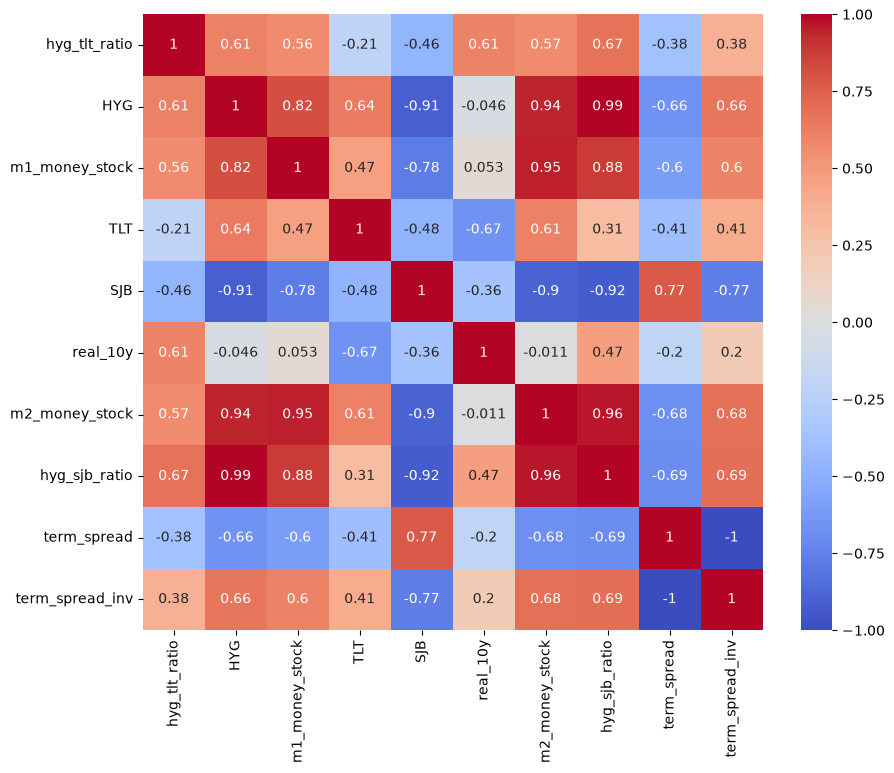

In [31]:
top_features = (
    factor_rank["factor"]
    .head(10)
    .tolist()
)

corr_matrix = (
    model_df[top_features]
    .corr()
)

display(corr_matrix)

plt.figure(figsize=(10,8))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm"
)
plt.show()

#### 11. Drawdown説明モデル作成

##### CSI_v4_equal

均等加重

In [32]:
selected_factors = [
    "hyg_tlt_ratio",
    "SJB",
    "real_10y",
    "m2_mom"
]

csi_df = model_df.copy()

csi_df["CSI_v4_equal"] = (
    csi_df[selected_factors]
    .mean(axis=1)
)

##### CSI_v4_weighted

相関係数重み

In [33]:
weights = {
    "m2_mom":0.288,
    "real_10y":0.183,
    "SJB":0.166,
    "hyg_tlt_ratio":0.158
}

weight_sum = sum(weights.values())

for k in weights:
    weights[k] /= weight_sum

csi_df["CSI_v4_weighted"] = (
      csi_df["m2_mom"]       * weights["m2_mom"]
    + csi_df["real_10y"]     * weights["real_10y"]
    + csi_df["SJB"]          * weights["SJB"]
    + csi_df["hyg_tlt_ratio"]* weights["hyg_tlt_ratio"]
)

#### 12. CSI検証

##### 12-A Pearson

In [34]:
pearson_equal = (
    csi_df["CSI_v4_equal"]
    .corr(
        csi_df["hyg_forward_3m"]
    )
)

pearson_weighted = (
    csi_df["CSI_v4_weighted"]
    .corr(
        csi_df["hyg_forward_3m"]
    )
)

print("equal =", pearson_equal)
print("weighted =", pearson_weighted)

equal = 0.07832723368406375
weighted = 0.29672606470275587


##### 12-B Spearman

In [35]:
from scipy.stats import spearmanr

tmp = csi_df[
    [
        "CSI_v4_equal",
        "CSI_v4_weighted",
        "hyg_forward_3m"
    ]
].dropna()

print(
    spearmanr(
        tmp["CSI_v4_equal"],
        tmp["hyg_forward_3m"]
    )
)

print(
    spearmanr(
        tmp["CSI_v4_weighted"],
        tmp["hyg_forward_3m"]
    )
)

SignificanceResult(statistic=np.float64(0.23651056616131455), pvalue=np.float64(0.0012279582636883636))
SignificanceResult(statistic=np.float64(0.2654254396948624), pvalue=np.float64(0.0002711546840512019))


##### 12-C Rank IC

In [36]:
csi_df["rank_equal"] = (
    csi_df["CSI_v4_equal"]
    .rank()
)

csi_df["rank_target"] = (
    csi_df["hyg_forward_3m"]
    .rank()
)

rank_ic = (
    csi_df["rank_equal"]
    .corr(
        csi_df["rank_target"]
    )
)

print(rank_ic)

0.10948538485164347


##### 12-D 可視化

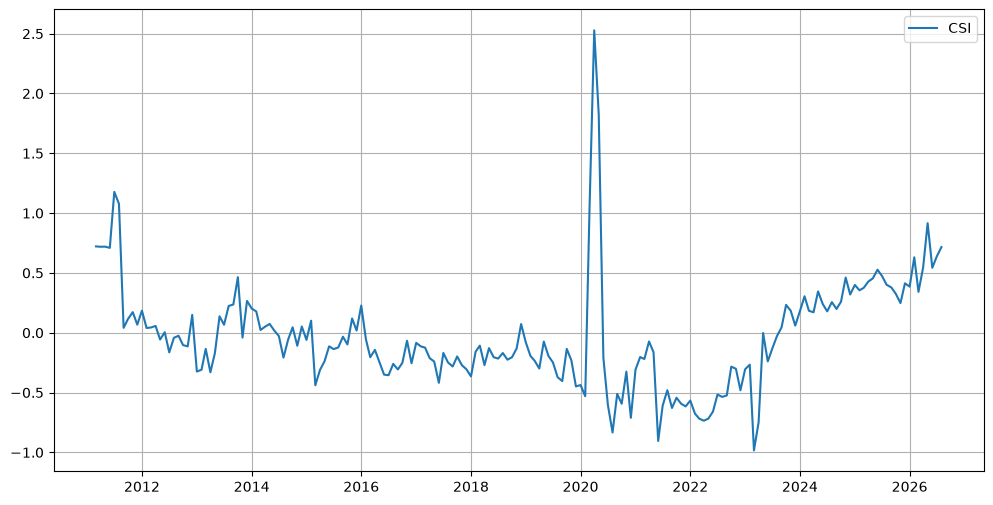

In [37]:
plt.figure(figsize=(12,6))

plt.plot(
    csi_df["date"],
    csi_df["CSI_v4_weighted"],
    label="CSI"
)

plt.legend()
plt.grid()
plt.show()

# Credit Stress Index V4 検証結果サマリー

## 目的

HYG（米国ハイイールド債ETF）の将来リターンおよび将来ドローダウンを説明する Credit Stress Index (CSI) の構築を目的として検証を実施した。

---

# V4 構築フロー

## 使用データ

### ETF

- HYG
- SJB
- TLT
- DXY

### FRED

- Effective Federal Funds Rate
- Fed Funds Rate
- Real 10Y Yield
- US Treasury 2Y
- US Treasury 5Y
- US Treasury 10Y
- US Treasury 30Y
- M1
- M2

---

## 派生ファクター

### 金利系

- real_10y
- term_spread
- term_spread_inv

### 流動性系

- m1_yoy
- m2_yoy
- m2_mom

### ETF系

- hyg_tlt_ratio
- hyg_sjb_ratio

---

# 目的変数

## Future Return

```python
hyg_forward_3m
```

3ヶ月後の HYG リターン

---

## Future Drawdown

```python
hyg_maxdd_3m
```

今後3ヶ月以内の最大下落率

---

# 単独因子分析結果

上位因子

| Rank | Factor | Spearman |
|--------|--------|--------:|
| 1 | hyg_tlt_ratio | -0.167 |
| 2 | HYG | -0.162 |
| 3 | m1_money_stock | -0.142 |
| 4 | TLT | -0.138 |
| 5 | SJB | 0.121 |
| 6 | real_10y | 0.116 |

### 考察

- HYG/TLT比率が最も高い説明力を持った
- 単独因子で強い相関を持つものは存在しなかった
- Spearman絶対値は最大でも0.17程度であった

---

# Lead/Lag分析結果

上位因子

| Factor | Lag | Correlation |
|----------|-----:|-----------:|
| m2_mom | -4 | -0.288 |
| m2_mom | -3 | -0.251 |
| real_10y | +5 | 0.183 |
| SJB | +6 | 0.166 |
| hyg_tlt_ratio | -6 | 0.159 |

### 考察

M2の月次増加率が最も有効な先行シグナルとなった。

特に

```text
M2増加
↓
3～4ヶ月後
↓
HYGへ影響
```

という流動性経路が示唆された。

---

# 共線性分析結果

以下の強い共線性を確認した。

## 非常に高い共線性

```text
HYG ↔ hyg_sjb_ratio
corr = 0.99

HYG ↔ m2_money_stock
corr = 0.94

m1_money_stock ↔ m2_money_stock
corr = 0.95

term_spread ↔ term_spread_inv
corr = -1.00
```

### 判断

全因子採用は不適切と判断。

---

# CSI_v4 構築

## CSI_v4_equal

構成因子

```python
[
    "hyg_tlt_ratio",
    "SJB",
    "real_10y",
    "m2_mom"
]
```

単純平均

---

## CSI_v4_weighted

Lead/Lag絶対相関を重み化

| Factor | Weight Source |
|----------|----------:|
| m2_mom | 0.288 |
| real_10y | 0.183 |
| SJB | 0.166 |
| hyg_tlt_ratio | 0.158 |

正規化後に加重平均を実施

---

# CSI検証結果

## Pearson Correlation

### CSI_v4_equal

```text
0.078
```

### CSI_v4_weighted

```text
0.297
```

---

## Spearman Correlation

### CSI_v4_equal

```text
0.237
p = 0.0012
```

### CSI_v4_weighted

```text
0.265
p = 0.00027
```

---

## Rank IC

```text
0.109
```

---

# 総合評価

## V4 Equal

評価

```text
失敗
```

理由

```text
説明力がほぼ存在しない
```

---

## V4 Weighted

評価

```text
部分成功
```

理由

```text
Pearson 0.297

Spearman 0.265
```

まで改善した。

Lead/Lag分析による重み付けは有効であることが確認できた。

---

# 今回得られた知見

## 確認できたこと

### 1.

流動性要因

```text
M2
```

が先行シグナルとして有効

---

### 2.

市場ストレス要因

```text
SJB
```

が中程度の先行性を持つ

---

### 3.

実質金利

```text
real_10y
```

はCredit Cycle説明因子として一定の有効性が存在

---

### 4.

HYG/TLT比率

```text
Risk-on / Risk-off
```

指標として有効

---

# V4の限界

V4では

```text
金利

流動性

債券ETF価格
```

のみを利用している。

一方でハイイールド債の下落は

```text
信用スプレッド

クレジット市場ストレス

市場ボラティリティ
```

にも大きく依存する。

そのため説明力は

```text
Pearson 0.30程度
```

に留まった。

---

# V5で追加検討すべき候補

優先度順

1. BAMLH0A0HYM2（HY OAS）
2. MOVE
3. VIXCLS
4. NFCI
5. WALCL
6. BBB OAS
7. CDX HY Proxy

---

# 最終結論

CSI V4 は

```text
方向性は正しい

しかし説明力は不十分
```

という結果であった。

一方で

```text
流動性(M2)

実質金利(Real Yield)

SJB

HYG/TLT
```

の有効性は確認できたため、

これらをCSI V5のコア因子として継続採用する価値がある。

以降の検証はv5で実施する

#### 13. Regime分析

#### 14. Regime別Drawdown分析

#### 15. ロジスティック回帰

#### 16. ROC-AUC評価

#### 17. Walk Forward検証

#### 18. Feature Importance

#### 19. V4最終サマリー

#### 20. V5候補検討